# 🌍 Global Earthquakes — Full Analysis
A comprehensive analysis of earthquake data: the countries most prone to earthquakes, the most powerful seismic events, tsunamis, and the tectonic context.

## 1. Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 110

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Libraries loaded successfully")

Libraries loaded successfully


## 2. Load the Dataset

In [ ]:

from google.colab import files
import pandas as pd

uploaded = files.upload()
FILE = list(uploaded.keys())[0]

df_raw = pd.read_csv(FILE)
df = df_raw.copy()

print(f"Loaded {FILE}: {df.shape[0]:,} rows × {df.shape[1]} columns")


Saving all_earthquakes_2000_2026_monthly.csv to all_earthquakes_2000_2026_monthly.csv
Loaded all_earthquakes_2000_2026_monthly.csv: 713,049 rows × 22 columns


## 3. Dataset Overview

In [ ]:
display(df.head())
print("\nShape:", df.shape)
print("\nColumns & dtypes:")
display(df.dtypes.astype(str).to_frame("dtype").T)

,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,net,id,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
0,2000-01-01T01:19:26.990Z,41.93,20.54,10.00,4.50,mb,NaN,NaN,NaN,1.14,us,usp0009kjw,2014-11-07T01:09:14.397Z,"14 km SW of Dragash, Kosovo",earthquake,NaN,NaN,NaN,18.00,reviewed,us,us
1,2000-01-01T02:10:15.590Z,41.91,20.53,6.20,2.90,md,NaN,NaN,NaN,NaN,us,usp0009kjx,2014-11-07T01:09:14.652Z,"15 km SW of Dragash, Kosovo",earthquake,NaN,NaN,NaN,NaN,reviewed,pdg,pdg
2,2000-01-01T02:12:13.450Z,-11.35,164.57,33.00,4.30,mb,NaN,NaN,NaN,1.16,us,usp0009kjz,2014-11-07T01:09:14.702Z,"150 km WSW of Lata, Solomon Islands",earthquake,NaN,NaN,NaN,2.00,reviewed,us,us
3,2000-01-01T03:20:57.300Z,48.12,-2.96,3.00,2.70,ml,NaN,NaN,NaN,NaN,us,usp0009kk0,2014-11-07T01:09:14.711Z,"2 km ESE of Neulliac, France",earthquake,NaN,NaN,NaN,NaN,reviewed,ldg,ldg
4,2000-01-01T03:24:23.217Z,62.75,-150.30,93.30,2.50,ml,NaN,NaN,NaN,0.78,ak,ak0001pgua9,2020-02-20T20:06:40.502Z,"35 km NNW of Chase, Alaska",earthquake,NaN,3.20,NaN,NaN,reviewed,ak,ak



Shape: (713049, 22)

Columns & dtypes:


,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,net,id,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
dtype,object,float64,float64,float64,float64,object,float64,float64,float64,float64,object,object,object,object,object,float64,float64,float64,float64,object,object,object


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 713049 entries, 0 to 713048
Data columns (total 22 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   time             713049 non-null  object 
 1   latitude         713049 non-null  float64
 2   longitude        713049 non-null  float64
 3   depth            713049 non-null  float64
 4   mag              713049 non-null  float64
 5   magType          713048 non-null  object 
 6   nst              478097 non-null  float64
 7   gap              594476 non-null  float64
 8   dmin             346751 non-null  float64
 9   rms              605453 non-null  float64
 10  net              713049 non-null  object 
 11  id               713049 non-null  object 
 12  updated          713049 non-null  object 
 13  place            713049 non-null  object 
 14  type             713049 non-null  object 
 15  horizontalError  351458 non-null  float64
 16  depthError       501056 non-null  floa

In [ ]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
time,713049,713028,2016-07-22T01:25:11.000Z,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,"713,049.00",NaN,NaN,NaN,19.23,30.59,-84.49,-5.07,20.72,43.20,87.39
longitude,"713,049.00",NaN,NaN,NaN,-21.33,123.21,-180.00,-130.02,-66.84,121.28,180.00
depth,"713,049.00",NaN,NaN,NaN,56.04,102.57,-3.74,10.00,20.00,51.40,735.80
mag,"713,049.00",NaN,NaN,NaN,3.80,0.87,0.70,2.93,4.00,4.50,9.10
magType,713048,27,mb,331709,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nst,"478,097.00",NaN,NaN,NaN,37.74,54.34,0.00,11.00,21.00,41.00,934.00
gap,"594,476.00",NaN,NaN,NaN,137.39,75.95,6.50,77.00,123.00,190.00,359.00
dmin,"346,751.00",NaN,NaN,NaN,2.43,4.15,0.00,0.35,1.13,2.85,127.42
rms,"605,453.00",NaN,NaN,NaN,0.70,0.41,-1.00,0.44,0.71,0.94,104.33


## 4. Data Quality Check

### 4.1 Missing Values ​​and Types


In [ ]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
display(quality)

,dtype,missing,missing_%,unique
time,object,0,0.00,713028
latitude,float64,0,0.00,362849
longitude,float64,0,0.00,450656
depth,float64,0,0.00,83576
mag,float64,0,0.00,493
magType,object,1,0.00,27
nst,float64,234952,32.95,740
gap,float64,118573,16.63,7758
dmin,float64,366298,51.37,44237
rms,float64,107596,15.09,2515


### 4.2  Duplicates


In [ ]:
key_cols = [
    c for c in ["date_time", "latitude", "longitude", "magnitude"]
    if c in df.columns
]

print("Full-row duplicates:", int(df.duplicated().sum()))
print(f"Duplicates on {key_cols}:", int(df.duplicated(subset=key_cols).sum()))

if key_cols and df.duplicated(subset=key_cols).any():
    display(
        df[df.duplicated(subset=key_cols, keep=False)]
        .sort_values(key_cols)
        .head(10)
    )

Full-row duplicates: 0
Duplicates on ['latitude', 'longitude']: 5203


,time,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,net,id,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource
218063,2008-03-31T08:33:12.000Z,-62.50,165.50,10.00,5.40,mwc,NaN,NaN,NaN,NaN,gcmt,gcmtc200803310833a,2016-11-10T01:53:49.259Z,Balleny Islands region,earthquake,NaN,NaN,NaN,NaN,automatic,gcmt,gcmt
249269,2009-05-23T09:03:20.000Z,-62.50,165.50,10.00,5.00,mwc,NaN,NaN,NaN,NaN,gcmt,gcmtc200905230903a,2016-11-10T02:12:16.579Z,Balleny Islands region,earthquake,NaN,NaN,NaN,NaN,automatic,gcmt,gcmt
252520,2009-08-13T12:14:48.000Z,-57.25,-141.75,10.00,5.20,mwc,NaN,NaN,NaN,NaN,gcmt,gcmtc200908131214a,2016-11-10T02:16:01.328Z,Pacific-Antarctic Ridge,earthquake,NaN,NaN,NaN,NaN,automatic,gcmt,gcmt
269637,2010-06-06T18:33:44.000Z,-57.25,-141.75,10.00,5.30,mwc,NaN,NaN,NaN,NaN,gcmt,gcmtc201006061833a,2016-11-10T02:29:14.286Z,Pacific-Antarctic Ridge,earthquake,NaN,NaN,NaN,NaN,automatic,gcmt,gcmt
75356,2003-07-09T13:59:11.910Z,-55.90,-27.45,114.90,4.60,mb,26.00,64.70,NaN,0.59,us,usp000c22m,2014-11-07T01:19:10.095Z,South Sandwich Islands region,earthquake,NaN,18.00,NaN,5.00,reviewed,us,us
149982,2006-02-19T15:53:32.510Z,-55.90,-27.45,117.60,4.70,mb,30.00,110.30,NaN,0.77,us,usp000eacs,2014-11-07T01:28:20.230Z,South Sandwich Islands region,earthquake,NaN,21.70,NaN,5.00,reviewed,us,us
160158,2006-06-12T00:43:12.000Z,-53.25,-117.75,10.00,5.10,mwc,NaN,NaN,NaN,NaN,gcmt,gcmtc200606120043a,2016-11-10T01:23:44.698Z,southern East Pacific Rise,earthquake,NaN,NaN,NaN,NaN,automatic,gcmt,gcmt
212523,2008-02-04T04:46:00.000Z,-53.25,-117.75,10.00,5.00,mwc,NaN,NaN,NaN,NaN,gcmt,gcmtc200802040446a,2016-11-10T01:51:28.870Z,southern East Pacific Rise,earthquake,NaN,NaN,NaN,NaN,automatic,gcmt,gcmt
169381,2006-09-15T06:37:04.000Z,-50.25,-115.75,10.00,5.20,mwc,NaN,NaN,NaN,NaN,gcmt,gcmtc200609150637a,2016-11-10T01:28:14.382Z,southern East Pacific Rise,earthquake,NaN,NaN,NaN,NaN,automatic,gcmt,gcmt
197530,2007-08-09T18:59:12.000Z,-50.25,-115.75,10.00,5.10,mwc,NaN,NaN,NaN,NaN,gcmt,gcmtc200708091859a,2016-11-10T01:43:22.538Z,southern East Pacific Rise,earthquake,NaN,NaN,NaN,NaN,automatic,gcmt,gcmt


### 4.3 Hidden Zeros
n some columns, the zero is not a true value.

In [ ]:
zero_candidates = [c for c in ["cdi", "mmi", "nst", "dmin", "gap", "sig", "depth", "tsunami"] if c in df.columns]
hz = pd.DataFrame({
    "zeros": (df[zero_candidates] == 0).sum(),
    "zeros_%": ((df[zero_candidates] == 0).mean() * 100).round(2),
})
display(hz)

HIDDEN_ZERO_COLS = [c for c in ["cdi", "mmi", "nst", "dmin", "gap"] if c in df.columns]
print("We will consider these zeros as missing values ​​hidden in:", HIDDEN_ZERO_COLS)

,zeros,zeros_%
nst,548,0.08
dmin,1521,0.21
gap,0,0.00
depth,10129,1.42


We will consider these zeros as missing values ​​hidden in: ['nst', 'dmin', 'gap']


### 4.4(`title`) with (`magnitude`)
The title appears in a format like `M 7.0 - 18 km SW of ...`; we extract the number and compare it with the `magnitude` column.

In [ ]:
if "title" in df.columns:
    title_mag = pd.to_numeric(
        df["title"].astype(str).str.extract(
            r"M\w*\s*([0-9]+\.?[0-9]*)"
        )[0],
        errors="coerce"
    )

    diff = (df["magnitude"] - title_mag).abs()

    print("Titles with a parsable magnitude:", int(title_mag.notna().sum()), "/", len(df))
    print("Mismatches (|diff| > 0.05)      :", int((diff > 0.05).sum()))

    if (diff > 0.05).any():
        display(
            df.loc[diff > 0.05, ["title", "magnitude"]]
            .assign(title_mag=title_mag[diff > 0.05])
            .head(15)
        )
    else:
        print("Titles are consistent with magnitude")
else:
    print("No title column found")

No title column found


### 4.5 Date Formats and Logical Ranges

In [ ]:
DATE_COL = "time"

print("Date column:", DATE_COL)
print("Sample raw values:", df[DATE_COL].astype(str).head(3).tolist())

print("Date column:", DATE_COL)

if DATE_COL is not None:
    print("Sample raw values:", df[DATE_COL].astype(str).head(3).tolist())
else:
    print("No date column found.")

checks = {}

if "magnitude" in df.columns:
    magnitude = pd.to_numeric(df["magnitude"], errors="coerce")
    checks["magnitude  [0, 10]"] = int(
        (~magnitude.between(0, 10)).sum()
    )

if "depth" in df.columns:
    depth = pd.to_numeric(df["depth"], errors="coerce")
    checks["depth سالب"] = int((depth < 0).sum())

if "latitude" in df.columns:
    latitude = pd.to_numeric(df["latitude"], errors="coerce")
    checks["latitude  [-90, 90]"] = int(
        (~latitude.between(-90, 90)).sum()
    )

if "longitude" in df.columns:
    longitude = pd.to_numeric(df["longitude"], errors="coerce")
    checks["longitude  [-180, 180]"] = int(
        (~longitude.between(-180, 180)).sum()
    )

if "tsunami" in df.columns:
    checks["tsunami  0/1"] = int(
        (~df["tsunami"].isin([0, 1])).sum()
    )

display(pd.Series(checks, name="count").to_frame())

Date column: time
Sample raw values: ['2000-01-01T01:19:26.990Z', '2000-01-01T02:10:15.590Z', '2000-01-01T02:12:13.450Z']
Date column: time
Sample raw values: ['2000-01-01T01:19:26.990Z', '2000-01-01T02:10:15.590Z', '2000-01-01T02:12:13.450Z']


,count
depth سالب,4806
"latitude خارج [-90, 90]",0
"longitude خارج [-180, 180]",0


## 5. Data Cleaning


In [ ]:
cleaning_log = []

def log(step, action, affected):
    cleaning_log.append({
        "step": step,
        "action": action,
        "rows/cells affected": affected
    })
def snapshot(d):
    g = lambda c: int(d[c].isna().sum()) if c in d.columns else 0
    hidden_zeros = (
        int((d[HIDDEN_ZERO_COLS] == 0).sum().sum())
        if HIDDEN_ZERO_COLS
        else 0
    )
    return {
        "rows": len(d),
        "columns": d.shape[1],
        "total missing cells": int(d.isna().sum().sum()),
        "duplicate rows": int(d.duplicated().sum()),
        "missing country": g("country"),
        "missing alert": g("alert"),
        "hidden zeros (cdi/mmi/nst/dmin/gap)": hidden_zeros,
        "time dtype": str(d[DATE_COL].dtype) if DATE_COL in d.columns else "Not found",
    }

before = snapshot(df)
print("Snapshot before cleaning saved")

Snapshot before cleaning saved


### Step 1 — Text cleaning (spaces + column names)

In [ ]:
df.columns = df.columns.str.strip()

obj_cols = df.select_dtypes(include=["object", "string"]).columns

for c in obj_cols:
    df[c] = df[c].astype("string").str.strip()

df = df.replace({"": pd.NA})

log(1, "Strip whitespace in text columns / column names", len(obj_cols))

### Step 2 — datatime




In [ ]:

df["date_time"] = pd.to_datetime(df["date_time"], errors="coerce")

before_rows = len(df)
df = df.dropna(subset=["date_time"]).copy()
failed = before_rows - len(df)

# Extract essential temporal features
df["year"] = df["date_time"].dt.year
df["month"] = df["date_time"].dt.month
df["hour"] = df["date_time"].dt.hour
df["date"] = df["date_time"].dt.date

# Record cleaning operations
log(
    2,
    "Ensure date_time format and extract year/month/hour/date",
    len(df)
)

log(
    "2b",
    "Dropped rows with invalid dates",
    failed
)

# Display results
print("Rows remaining:", len(df))
print("Rows dropped due to invalid dates:", failed)
print(
    "Date range:",
    df["date_time"].min(),
    "→",
    df["date_time"].max()
)

display(df[["date_time", "year", "month", "hour", "date"]].head())


Rows remaining: 713049
Rows dropped due to invalid dates: 0
Date range: 2000-01-01 01:19:26.990000+00:00 → 2026-12-10 23:47:23.932000+00:00


,date_time,year,month,hour,date
0,2000-01-01 01:19:26.990000+00:00,2000,1,1,2000-01-01
1,2000-01-01 02:10:15.590000+00:00,2000,1,2,2000-01-01
2,2000-01-01 02:12:13.450000+00:00,2000,1,2,2000-01-01
3,2000-01-01 03:20:57.300000+00:00,2000,1,3,2000-01-01
4,2000-01-01 03:24:23.217000+00:00,2000,1,3,2000-01-01


### Step 3 — Remove duplicates



In [ ]:

# Count rows before removing duplicates
n0 = len(df)

# Remove exact duplicate rows
df = df.drop_duplicates()
n1 = len(df)

# Identify columns used to detect possible duplicate earthquake events
key_cols = [
    c for c in ["date_time", "latitude", "longitude", "mag"]
    if c in df.columns
]

# Remove duplicates based on earthquake event details
if key_cols:
    df = df.drop_duplicates(subset=key_cols, keep="first")

# Record cleaning operations
log(3, "Dropped full-row duplicates", n0 - n1)
log("3b", f"Dropped duplicates based on {key_cols}", n1 - len(df))

# Reset row index
df = df.reset_index(drop=True)

print("Rows before cleaning:", n0)
print("Exact duplicate rows removed:", n0 - n1)
print("Additional duplicates removed by key:", n1 - len(df))
print("Rows remaining:", len(df))
print("Duplicate-check columns:", key_cols)


Rows before cleaning: 713049
Exact duplicate rows removed: 0
Additional duplicates removed by key: 6
Rows remaining: 713043
Duplicate-check columns: ['date_time', 'latitude', 'longitude', 'mag']


Step 4 — Converting hidden zeros to Nan

In [ ]:

# Check zero values in existing candidate columns
zero_candidates = [
    c for c in ["nst", "dmin", "gap", "depth", "magError", "magNst", "rms"]
    if c in df.columns
]

if zero_candidates:
    zero_report = pd.DataFrame({
        "zeros_count": (df[zero_candidates] == 0).sum(),
        "zeros_percentage": (
            (df[zero_candidates] == 0).mean() * 100
        ).round(2),
        "missing_count": df[zero_candidates].isna().sum()
    })

    display(zero_report.sort_values("zeros_count", ascending=False))
else:
    print("No candidate columns found.")

print("\nData has not been modified.")


,zeros_count,zeros_percentage,missing_count
depth,10129,1.42,0
magError,9912,1.39,359867
dmin,1521,0.21,366296
magNst,652,0.09,214006
nst,548,0.08,234949
rms,130,0.02,107596
gap,0,0.00,118571



Data has not been modified.


In [ ]:

print("Data shape:", df.shape)
print("\nCurrent columns:")
print(df.columns.tolist())

print("\nDate columns:")
print([c for c in df.columns if "time" in c.lower() or "date" in c.lower()])

print("\nMissing values in important columns:")
important_cols = [
    c for c in ["time", "date_time", "latitude", "longitude", "depth", "mag"]
    if c in df.columns
]

display(df[important_cols].isna().sum().to_frame("missing_count"))

print("\nFirst 3 rows:")
display(df.head(3))


Data shape: (713043, 26)

Current columns:
['latitude', 'longitude', 'depth', 'mag', 'magType', 'nst', 'gap', 'dmin', 'rms', 'net', 'id', 'updated', 'place', 'type', 'horizontalError', 'depthError', 'magError', 'magNst', 'status', 'locationSource', 'magSource', 'date_time', 'year', 'month', 'hour', 'date']

Date columns:
['updated', 'date_time', 'date']

Missing values in important columns:


,missing_count
date_time,0
latitude,0
longitude,0
depth,0
mag,0



First 3 rows:


,latitude,longitude,depth,mag,magType,nst,gap,dmin,rms,net,id,updated,place,type,horizontalError,depthError,magError,magNst,status,locationSource,magSource,date_time,year,month,hour,date
0,41.93,20.54,10.00,4.50,mb,NaN,NaN,NaN,1.14,us,usp0009kjw,2014-11-07T01:09:14.397Z,"14 km SW of Dragash, Kosovo",earthquake,NaN,NaN,NaN,18.00,reviewed,us,us,2000-01-01 01:19:26.990000+00:00,2000,1,1,2000-01-01
1,41.91,20.53,6.20,2.90,md,NaN,NaN,NaN,NaN,us,usp0009kjx,2014-11-07T01:09:14.652Z,"15 km SW of Dragash, Kosovo",earthquake,NaN,NaN,NaN,NaN,reviewed,pdg,pdg,2000-01-01 02:10:15.590000+00:00,2000,1,2,2000-01-01
2,-11.35,164.57,33.00,4.30,mb,NaN,NaN,NaN,1.16,us,usp0009kjz,2014-11-07T01:09:14.702Z,"150 km WSW of Lata, Solomon Islands",earthquake,NaN,NaN,NaN,2.00,reviewed,us,us,2000-01-01 02:12:13.450000+00:00,2000,1,2,2000-01-01


### Step 5 — اتساق `title` مع `magnitude`

In [ ]:
FIX_FROM_TITLE = False   # خليها True لو عايز تعتمد الرقم اللي في العنوان

if "title" in df.columns:
    t_mag = pd.to_numeric(df["title"].astype(str).str.extract(r"M\w*\s*([0-9]+\.?[0-9]*)")[0], errors="coerce")
    bad = (df["magnitude"] - t_mag).abs() > 0.05
    df["title_mismatch"] = bad.fillna(False)
    if FIX_FROM_TITLE:
        df.loc[bad, "magnitude"] = t_mag[bad]
    log(5, f"Flagged title/magnitude mismatches (FIX_FROM_TITLE={FIX_FROM_TITLE})", int(bad.sum()))
else:
    log(5, "No title column — skipped", 0)

### Step 8 — تصنيفات جديدة (عمق + فئة القوة)

In [ ]:

# Step 8: Create earthquake depth and magnitude categories

# Classify earthquakes by depth
df["depth_class"] = pd.cut(
    df["depth"],
    bins=[-np.inf, 70, 300, np.inf],
    labels=[
        "Shallow (<70 km)",
        "Intermediate (70–300 km)",
        "Deep (>300 km)"
    ],
    right=False
)

# Classify earthquakes by magnitude
df["mag_class"] = pd.cut(
    df["mag"],
    bins=[-np.inf, 6.5, 7.0, 7.5, 8.0, np.inf],
    labels=[
        "<6.5",
        "6.5–6.9",
        "7.0–7.4",
        "7.5–7.9",
        "8.0+"
    ],
    right=False
)

# Record the operation
log(
    8,
    "Added depth_class and mag_class",
    len(df)
)

# Preview the new columns
display(df[["depth", "depth_class", "mag", "mag_class"]].head())

print("\nDepth category counts:")
display(df["depth_class"].value_counts(dropna=False))

print("\nMagnitude category counts:")
display(df["mag_class"].value_counts(dropna=False))


,depth,depth_class,mag,mag_class
0,10.00,Shallow (<70 km),4.50,<6.5
1,6.20,Shallow (<70 km),2.90,<6.5
2,33.00,Shallow (<70 km),4.30,<6.5
3,3.00,Shallow (<70 km),2.70,<6.5
4,93.30,Intermediate (70–300 km),2.50,<6.5



Depth category counts:


,count
depth_class,
Shallow (<70 km),572117
Intermediate (70–300 km),113844
Deep (>300 km),27082



Magnitude category counts:


,count
mag_class,
<6.5,711820
6.5–6.9,823
7.0–7.4,256
7.5–7.9,116
8.0+,28


### 🧾 Cleaning Log + جدول قبل وبعد

In [ ]:
display(pd.DataFrame(cleaning_log))

after = snapshot(df)
comparison = pd.DataFrame({"Before": before, "After": after})
comparison["Change"] = [
    (a - b) if isinstance(a, (int, float)) and isinstance(b, (int, float)) else "—"
    for b, a in zip(comparison["Before"], comparison["After"])
]
display(comparison)

,step,action,rows/cells affected
0,1,Strip whitespace in text columns / column names,10
1,2,Ensure date_time format and extract year/month...,713049
2,2b,Dropped rows with invalid dates,0
3,3,Dropped full-row duplicates,0
4,3b,"Dropped duplicates based on ['date_time', 'lat...",6
5,5,No title column — skipped,0
6,8,Added depth_class and mag_class,713043


,Before,After,Change
rows,713049,713043,-6
columns,22,28,6
total missing cells,1974882,1974868,-14
duplicate rows,0,0,0
missing country,0,0,0
missing alert,0,0,0
hidden zeros (cdi/mmi/nst/dmin/gap),2069,2069,0
time dtype,object,Not found,—


## 6. Exploratory Data Analysis (EDA)

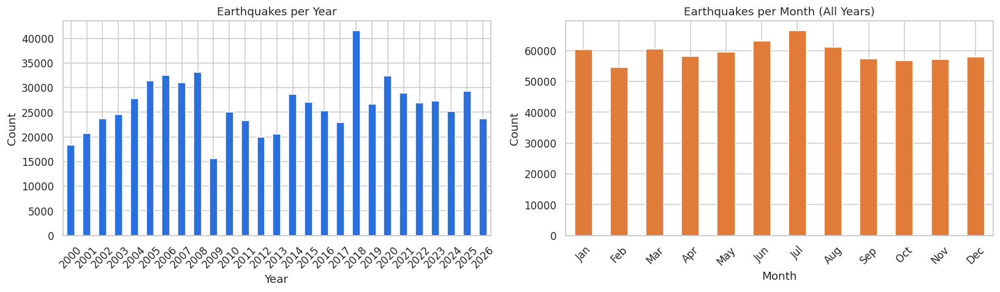

In [ ]:

# Step 9: Temporal analysis — yearly and monthly earthquake counts

# Number of earthquakes per year
yearly = df.groupby("year").size()

# Number of earthquakes per month across all years
monthly = (
    df.groupby("month")
      .size()
      .reindex(range(1, 13), fill_value=0)
)

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

# Yearly chart
yearly.plot(
    kind="bar",
    ax=ax[0],
    color="#2a6fdb"
)
ax[0].set_title("Earthquakes per Year")
ax[0].set_xlabel("Year")
ax[0].set_ylabel("Count")
ax[0].tick_params(axis="x", rotation=45)

# Monthly chart
monthly.plot(
    kind="bar",
    ax=ax[1],
    color="#e07b39"
)
ax[1].set_title("Earthquakes per Month (All Years)")
ax[1].set_xlabel("Month")
ax[1].set_ylabel("Count")
ax[1].set_xticklabels(month_labels, rotation=45)

plt.tight_layout()
plt.show()


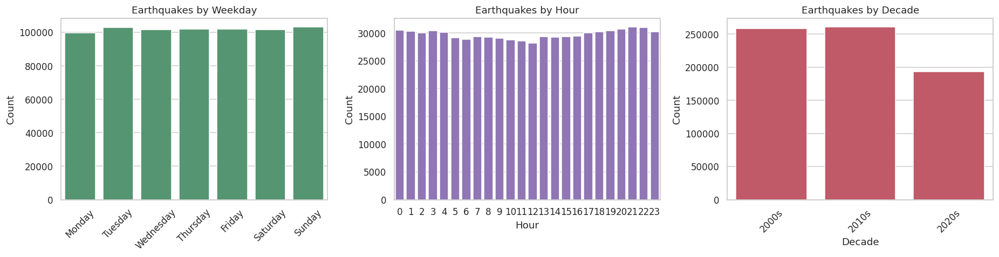

In [ ]:

# Step 10: Temporal distribution by weekday, hour, and decade

# Derive features for this analysis only
weekday = df["date_time"].dt.day_name()
decade = (df["date_time"].dt.year // 10 * 10).astype(str) + "s"

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# Earthquakes by weekday
sns.countplot(
    x=weekday,
    order=weekday_order,
    ax=ax[0],
    color="#4c9f70"
)
ax[0].set_title("Earthquakes by Weekday")
ax[0].tick_params(axis="x", rotation=45)
ax[0].set_xlabel("")
ax[0].set_ylabel("Count")

# Earthquakes by hour (UTC if source timestamps are UTC)
sns.countplot(
    x=df["hour"],
    ax=ax[1],
    color="#8e6bbf"
)
ax[1].set_title("Earthquakes by Hour")
ax[1].set_xlabel("Hour")
ax[1].set_ylabel("Count")

# Earthquakes by decade
decade_order = sorted(decade.unique())
sns.countplot(
    x=decade,
    order=decade_order,
    ax=ax[2],
    color="#d1495b"
)
ax[2].set_title("Earthquakes by Decade")
ax[2].set_xlabel("Decade")
ax[2].set_ylabel("Count")
ax[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


###  Countries most prone to earthquakes


In [ ]:

# Step 11: Analyze earthquake counts by location

top_locations = (
    df.groupby("place")
      .agg(
          earthquakes=("mag", "size"),
          avg_magnitude=("mag", "mean"),
          max_magnitude=("mag", "max"),
          avg_depth=("depth", "mean")
      )
      .sort_values("earthquakes", ascending=False)
)

top_locations["share_%"] = (
    top_locations["earthquakes"] / len(df) * 100
)

display(
    top_locations.head(15).style
    .background_gradient(subset=["earthquakes"], cmap="Reds")
    .format({
        "avg_magnitude": "{:.2f}",
        "max_magnitude": "{:.1f}",
        "avg_depth": "{:.1f}",
        "share_%": "{:.2f}%"
    })
)

# Plot the 15 most frequently recorded locations
top15 = top_locations.head(15).reset_index()

fig = px.bar(
    top15.sort_values("earthquakes"),
    x="earthquakes",
    y="place",
    orientation="h",
    color="max_magnitude",
    color_continuous_scale="YlOrRd",
    title="Top 15 Locations by Number of Earthquake Records",
    text="earthquakes",
    hover_data=["avg_magnitude", "avg_depth", "share_%"]
)

fig.update_layout(
    height=600,
    yaxis_title="",
    xaxis_title="Number of Records",
    coloraxis_colorbar_title="Max Magnitude"
)

fig.show()


,earthquakes,avg_magnitude,max_magnitude,avg_depth,share_%
place,,,,,
South Sandwich Islands region,7517,4.66,7.5,42.3,1.05%
south of the Fiji Islands,7384,4.48,7.8,438.8,1.04%
"Rat Islands, Aleutian Islands, Alaska",5413,3.26,7.9,59.3,0.76%
Fiji region,5208,4.41,7.7,531.5,0.73%
Kermadec Islands region,5133,4.61,7.6,86.5,0.72%
south of the Kermadec Islands,3534,4.58,7.4,52.8,0.50%
"Izu Islands, Japan region",3156,4.45,6.8,103.2,0.44%
"Kermadec Islands, New Zealand",2889,4.67,7.4,46.6,0.41%
"5 km SW of Volcano, Hawaii",2866,2.77,5.3,0.7,0.40%


## 7. Magnitude and Depth

/tmp/ipykernel_548/1363081912.py:16: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




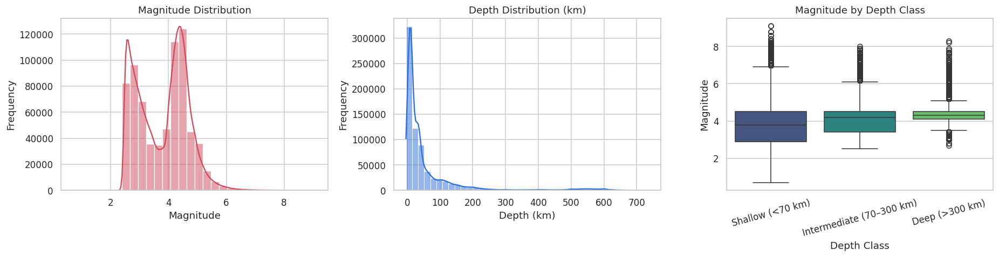

In [ ]:

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# 1. Magnitude Distribution
sns.histplot(df["mag"].dropna(), bins=30, kde=True, ax=ax[0], color="#d1495b")
ax[0].set_title("Magnitude Distribution")
ax[0].set_xlabel("Magnitude")
ax[0].set_ylabel("Frequency")

# 2. Depth Distribution
sns.histplot(df["depth"].dropna(), bins=40, kde=True, ax=ax[1], color="#2a6fdb")
ax[1].set_title("Depth Distribution (km)")
ax[1].set_xlabel("Depth (km)")
ax[1].set_ylabel("Frequency")

# 3. Magnitude by Depth Class
sns.boxplot(data=df, x="depth_class", y="mag", ax=ax[2], palette="viridis")
ax[2].set_title("Magnitude by Depth Class")
ax[2].set_xlabel("Depth Class")
ax[2].set_ylabel("Magnitude")
ax[2].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


/tmp/ipykernel_548/2610567567.py:22: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




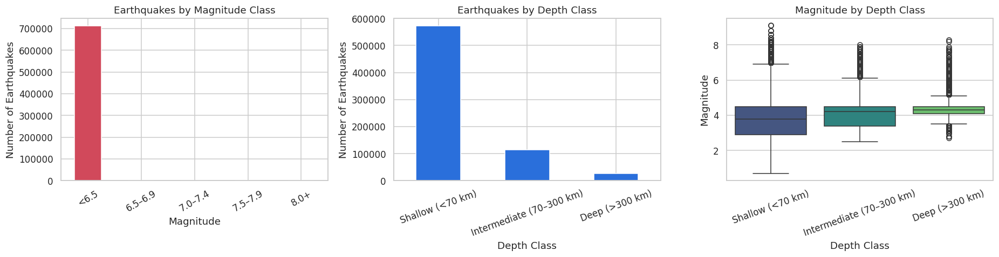

In [ ]:

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# 1. Earthquakes by Magnitude Class
df["mag_class"].value_counts().sort_index().plot(
    kind="bar", ax=ax[0], color="#d1495b"
)
ax[0].set_title("Earthquakes by Magnitude Class")
ax[0].set_xlabel("Magnitude")
ax[0].set_ylabel("Number of Earthquakes")
ax[0].tick_params(axis="x", rotation=30)

# 2. Earthquakes by Depth Class
df["depth_class"].value_counts().sort_index().plot(
    kind="bar", ax=ax[1], color="#2a6fdb"
)
ax[1].set_title("Earthquakes by Depth Class")
ax[1].set_xlabel("Depth Class")
ax[1].set_ylabel("Number of Earthquakes")
ax[1].tick_params(axis="x", rotation=20)

# 3. Magnitude by Depth Class
sns.boxplot(
    data=df, x="depth_class", y="mag",
    ax=ax[2], palette="viridis"
)
ax[2].set_title("Magnitude by Depth Class")
ax[2].set_xlabel("Depth Class")
ax[2].set_ylabel("Magnitude")
ax[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


## 9. Geographic Analysis

In [ ]:

# Geographic Distribution of Earthquakes

fig = px.scatter_geo(
    df,
    lat="latitude",
    lon="longitude",
    color="mag",
    size="mag",
    hover_name="place",
    hover_data={
        "depth": True,
        "date_time": True,
        "latitude": True,
        "longitude": True
    },
    color_continuous_scale="YlOrRd",
    projection="natural earth",
    title="Earthquake Locations — Colored by Magnitude",
    opacity=0.7,
    size_max=12
)

fig.update_layout(height=600)
fig.show()


Buffered data was truncated after reaching the output size limit.

In [40]:
try:
    if hasattr(px, "density_map"):          # plotly >= 5.24
        fig = px.density_map(df, lat="latitude", lon="longitude", z="magnitude", radius=8,
                             center=dict(lat=10, lon=140), zoom=0.8, map_style="carto-positron",
                             title="Earthquake Density Heatmap (Ring of Fire is obvious)")
    else:                                    # older plotly
        fig = px.density_mapbox(df, lat="latitude", lon="longitude", z="magnitude", radius=8,
                                center=dict(lat=10, lon=140), zoom=0.8, mapbox_style="carto-positron",
                                title="Earthquake Density Heatmap (Ring of Fire is obvious)")
except Exception:
    fig = px.density_heatmap(df, x="longitude", y="latitude", nbinsx=90, nbinsy=45, color_continuous_scale="YlOrRd",
                             title="Earthquake Density Heatmap (lon/lat bins)")
fig.update_layout(height=600); fig.show()

## 10. Causes of the Earthquakes (السياق التكتوني)

الأرض قشرتها مقسّمة لصفائح تكتونية بتتحرك بسرعة سنتيمترات في السنة. الزلازل الكبيرة بتحصل غالبًا عند حدود الصفائح:

| نوع الحد | اللي بيحصل | أمثلة |
|---|---|---|
| **Subduction (اندساس)** | صفيحة محيطية بتغطس تحت صفيحة تانية → أقوى الزلازل وأخطرها وبتسبب التسونامي (Megathrust) | اليابان، تشيلي، إندونيسيا، ألاسكا |
| **Collision (تصادم قاري)** | صفيحتين قاريتين بيتصادموا فبيترفع الجبل | الهيمالايا (نيبال، الهند)، إيران، تركيا |
| **Transform (انزلاق جانبي)** | صفيحتين بتحتكّوا جنب بعض | فالق سان أندرياس (كاليفورنيا)، فالق شمال الأناضول |
| **Divergent (تباعد)** | صفيحتين بتبعدوا → زلازل أصغر وضحلة | وسط الأطلسي، شرق أفريقيا |

- **حزام النار (Ring of Fire)** حوالي المحيط الهادي: فيه تقريبًا 90% من زلازل العالم و~80% من أكبرها.
- **حزام ألبايد (Alpide Belt)** من المتوسط لآسيا: تاني أكبر مصدر للزلازل.
- **العمق**: الزلازل العميقة (>300 كم) بتحصل بس في مناطق الاندساس لأن الصفيحة الغاطسة بتفضل باردة وصلبة.
- **التسونامي** بيحتاج زلزال بحري، ضحل، قوي (غالبًا M ≥ 7) وبحركة رأسية في قاع البحر.

In [ ]:
RING_OF_FIRE = {"Japan","Indonesia","Philippines","Papua New Guinea","New Zealand","Chile","Peru","Ecuador","Colombia",
                "Mexico","Guatemala","El Salvador","Nicaragua","Costa Rica","Panama","Tonga","Fiji","Vanuatu",
                "Solomon Islands","Taiwan","Russia","United States","Canada","Argentina","Bolivia","New Caledonia",
                "Samoa","American Samoa","Kiribati","Northern Mariana Islands","Guam"}
ALPIDE = {"Turkey","Iran","Pakistan","Afghanistan","Nepal","India","China","Myanmar","Greece","Italy","Tajikistan",
          "Kyrgyzstan","Georgia","Armenia","Azerbaijan","Iraq","Algeria","Morocco","Albania","Bosnia and Herzegovina",
          "Croatia","Romania","Bhutan","Bangladesh","Egypt","Syria","Lebanon","Israel"}

def tectonic_belt(c):
    if c in RING_OF_FIRE: return "Pacific Ring of Fire"
    if c in ALPIDE:       return "Alpide Belt"
    return "Other (ridges / intraplate / ocean)"

df["tectonic_belt"] = df["country"].map(tectonic_belt)
belt = df.groupby("tectonic_belt").agg(earthquakes=("magnitude", "size"), avg_mag=("magnitude", "mean"),
                                       avg_depth=("depth", "mean"), tsunamis=("tsunami", "sum"))
belt["share_%"] = belt["earthquakes"] / belt["earthquakes"].sum() * 100
display(belt.round(2))
print("⚠️ التصنيف تقريبي على مستوى الدولة (مش على مستوى الفالق)")

px.pie(belt.reset_index(), names="tectonic_belt", values="earthquakes", hole=.45,
       title="Share of earthquakes by tectonic belt (approx.)").show()

In [ ]:
fig = px.scatter_geo(df, lat="latitude", lon="longitude", color="depth_class", opacity=.6,
                     projection="natural earth", title="Depth class map — deep quakes trace subduction zones",
                     color_discrete_sequence=["#f4a261", "#2a9d8f", "#264653"])
fig.update_layout(height=550); fig.show()

## 11. Correlation Analysis

## 12. Explore Significant Earthquakes — أقوى 10 زلازل

In [46]:

cols_show = [
    c for c in [
        "time", "place", "mag", "depth",
        "alert", "tsunami", "mmi", "magType"
    ]
    if c in df.columns
]

top10 = df.sort_values(
    "mag",
    ascending=False
).head(10).reset_index(drop=True)

top10.index = top10.index + 1
top10.index.name = "rank"

display(top10[cols_show])


,place,mag,depth,magType
rank,,,,
1,2004 Sumatra - Andaman Islands Earthquake,9.10,30.00,mw
2,"2011 Great Tohoku Earthquake, Japan",9.10,29.00,mww
3,"2025 Kamchatka Peninsula, Russia Earthquake",8.80,35.00,mww
4,"2010 Maule, Chile Earthquake",8.80,22.90,mww
5,2012 Wharton Basin Earthquake,8.60,20.00,mw
6,"78 km WSW of Singkil, Indonesia",8.60,30.00,mww
7,"6 km SSW of Atico, Peru",8.40,33.00,mww
8,"122 km SW of Bengkulu, Indonesia",8.40,34.00,mww
9,2013 Sea of Okhotsk Earthquake,8.30,598.10,mww


In [48]:
print("Top 10 Earthquakes by Magnitude (mag):")

display(
    df.sort_values("mag", ascending=False)
      .head(10)[cols_show]
      .reset_index(drop=True)
)

Top 10 Earthquakes by Magnitude (mag):


,place,mag,depth,magType
0,2004 Sumatra - Andaman Islands Earthquake,9.10,30.00,mw
1,"2011 Great Tohoku Earthquake, Japan",9.10,29.00,mww
2,"2025 Kamchatka Peninsula, Russia Earthquake",8.80,35.00,mww
3,"2010 Maule, Chile Earthquake",8.80,22.90,mww
4,2012 Wharton Basin Earthquake,8.60,20.00,mw
5,"78 km WSW of Singkil, Indonesia",8.60,30.00,mww
6,"6 km SSW of Atico, Peru",8.40,33.00,mww
7,"122 km SW of Bengkulu, Indonesia",8.40,34.00,mww
8,2013 Sea of Okhotsk Earthquake,8.30,598.10,mww
9,2006 Kuril Islands Earthquake,8.30,10.00,mwc


## 13. Key Insights

In [50]:
n = len(df)
yr0, yr1 = int(df["year"].min()), int(df["year"].max())

strongest = df.loc[df["mag"].idxmax()]
peak_year = df["year"].value_counts().idxmax()

print(f"""
📊 KEY INSIGHTS
{'='*70}
1. Dataset: {n:,} earthquake records between {yr0} and {yr1}.
2. Strongest earthquake: Magnitude {strongest['mag']:.1f}, depth {strongest['depth']:.0f} km.
3. Busiest year: {peak_year} ({int(df['year'].value_counts().max())} events).
""")


📊 KEY INSIGHTS
1. Dataset: 713,043 earthquake records between 2000 and 2026.
2. Strongest earthquake: Magnitude 9.1, depth 30 km.
3. Busiest year: 2018 (41505 events).



In [51]:
df.to_csv("earthquake_data_cleaned.csv", index=False)

from google.colab import files
files.download("earthquake_data_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### ملاحظات ختامية
- الداتا فيها زلازل **كبيرة/مهمة** بس (مش كل الزلازل الصغيرة)، فالأعداد مش تمثّل النشاط الزلزالي الكامل.
- تصنيف الحزام التكتوني تقريبي على مستوى الدولة.
- تقدر تغيّر `FIX_FROM_TITLE = True` في Step 5 لو عايز تعتمد القوة المكتوبة في العنوان.